In [1]:
import rbfopt
import numpy as np
import warnings
warnings.filterwarnings("ignore", message="Signature .* for <class 'numpy.longdouble'> does not match any known type")
import csv

/home/albertlee/miniconda3/envs/rbfopt/lib/python3.13/site-packages/numpy/_core/getlimits.py:551: UserWarning: Signature b'\x00\xd0\xcc\xcc\xcc\xcc\xcc\xcc\xfb\xbf\x00\x00\x00\x00\x00\x00' for <class 'numpy.longdouble'> does not match any known type: falling back to type probe function.
This warnings indicates broken support for the dtype!
  machar = _get_machar(dtype)


In [2]:
def load_grid(filename="compl_enum_cstr_30_baron_hull.csv"):
    """
    Load grid data from CSV.
    Expected CSV columns: "x", "y", "Objective", among others.
    Returns a dictionary mapping (x, y) tuples to the objective value.
    """
    grid_data = {}
    with open(filename, "r") as f:
        reader = csv.DictReader(f)
        for row in reader:
            try:
                # Convert x and y values to integers
                x_val = int(row["x"])
                y_val = int(row["y"])
                # Skip rows where either x or y is greater than 7
                if x_val > 7 or y_val > 7:
                    continue
                # Convert objective value to float
                obj_val = float(row["Objective"])
                grid_data[(x_val, y_val)] = obj_val
            except Exception as e:
                # Skip rows with conversion issues
                continue
    return grid_data
# Load the data from grid.csv
grid_data = load_grid()

# Determine grid bounds from the keys of grid_data
xs = [pt[0] for pt in grid_data.keys()]
ys = [pt[1] for pt in grid_data.keys()]
min_x, max_x = min(xs), max(xs)
min_y, max_y = min(ys), max(ys)
print("Grid bounds:")
print("x in [{}, {}]".format(min_x, max_x))
print("y in [{}, {}]".format(min_y, max_y))

Grid bounds:
x in [1, 7]
y in [1, 7]


In [3]:
# Load the data from grid.csv
grid_data = load_grid()

# PENALTY = 1e5  # adjust this penalty as appropriate
PENALTY = np.inf # use infinity as penalty for infeasible points
# PENALTY = np.nan  # use NaN as penalty for infeasible points
# PENALTY = None  # use None as penalty for infeasible points

def obj_funct(x):
    """
    Given a candidate point x (a list or 1-D numpy array with 2 elements),
    this function rounds x to the nearest integers and returns the objective value
    if the point exists in grid_data and is feasible (i.e. y <= x).
    Otherwise, returns a penalty value.
    """
    # Round the candidate coordinates to nearest integers
    x_int = int(round(x[0]))
    y_int = int(round(x[1]))
    
    # Check the feasibility of the point: for our lattice we require y <= x.
    if y_int > x_int:
        return PENALTY
    
    # If the point exists in the grid, return its objective value.
    if (x_int, y_int) in grid_data:
        return grid_data[(x_int, y_int)]
    else:
        # If the point is not in the grid, return the penalty.
        return PENALTY

In [4]:
test_point = [7,7]
value = obj_funct(test_point)
print(f"For point {test_point} the objective value is {value}")

For point [7, 7] the objective value is 2.965911187241821


In [5]:
# Set up the black-box for a 2D problem with integer variables.
# We use the determined bounds and mark both variables as integer ("I").
black_box = rbfopt.RbfoptUserBlackBox(
    2,
    np.array([1, 1]),    # lower bounds for x and y
    np.array([7, 7]),  # upper bounds for x and y
    np.array(["I", "I"]),# both variables are integers
    obj_funct
)

# Configure optimization settings.
settings = rbfopt.RbfoptSettings(
    max_evaluations=9,  # maximum number of evaluations
    minlp_solver_path='/home/albertlee/ampl.linux-intel64/bonmin',
    nlp_solver_path='/home/albertlee/ampl.linux-intel64/ipopt',
    algorithm='MSRSM',   # optimization algorithm variant
    rbf='auto',           # allow automatic RBF selection
    global_search_method = 'solver',  # options = ['sampling', 'genetic', 'solver']
)

# Create the optimization algorithm instance.
alg = rbfopt.RbfoptAlgorithm(settings, black_box)

# Run the optimization.
best_val, best_point, itercount, evalcount, fast_evalcount = alg.optimize()

print("Optimization completed.")
print("Best objective value found:", best_val)
print("At lattice point (rounded):", [int(round(v)) for v in best_point])
print("Iterations:", itercount, "Function evaluations:", evalcount)

  Iter  Cycle  Action             Objective value      Time      Gap
  ----  -----  ------             ---------------      ----      ---
     0      0  Initialization            2.965911      0.00   100.00 *
     0      0  Initialization            4.061882      0.01   100.00  
     0      0  Initialization            3.133784      0.01   100.00  
     0      0  GlobalStep                     inf      0.30   100.00  
     1      0  GlobalStep                3.287151      0.50   100.00  
     2      0  GlobalStep                     inf      0.85   100.00  
     3      0  GlobalStep                3.269434      1.04   100.00  
     4      0  GlobalStep                3.007278      1.37   100.00  
     5      1  Discarded                               1.87
     6      1  GlobalStep                3.062015      2.29   100.00  
Summary: iters   7 evals   9 noisy_evals   0 cycles   1 opt_time    2.29 tot_time    2.29 obj         2.965911 gap 100.00
Trajectory: 
Iter   0 Obj        2.965911

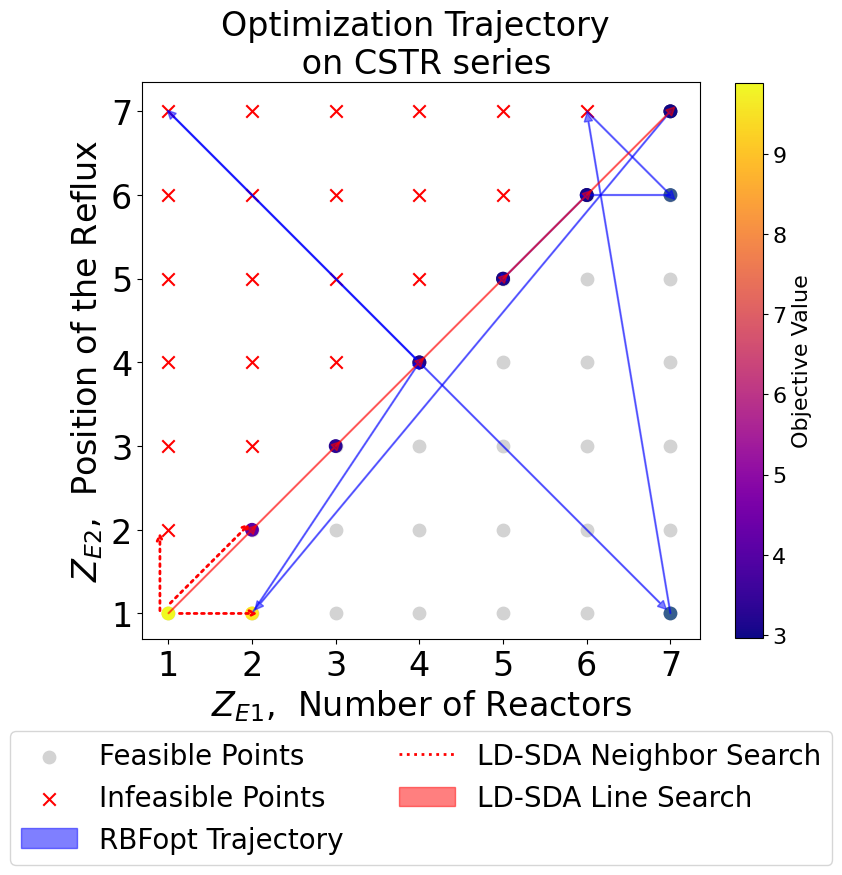

In [6]:
import matplotlib.pyplot as plt
import numpy as np
# Data from the iterations
# iterations = [
#     (0, float('inf'), [27., 30.]),
#     (1, 3.287151, [7., 1.]),
#     (2, 2.821876, [16., 16.]),
#     (3, float('inf'), [1., 30.]),
#     (4, 3.652690, [26., 1.]),
#     (5, float('inf'), [7., 30.]),
#     (6, 2.821876, [16., 16.]),
#     (7, 9.884852, [1., 1.]),
#     (8, 2.769570, [30., 30.]),
#     (9, 3.248530, [25., 21.]),
#     (10, float('inf'), [29., 30.]),
#     (11, 3.256144, [30., 25.]),
#     (12, 2.860112, [30., 29.]),
#     (13, float('inf'), [15., 16.]),
#     (14, 2.981420, [17., 16.]),
#     (15, 3.156468, [17., 15.]),
#     (16, 2.954869, [30., 28.]),
#     (17, 2.781482, [25., 25.]),
#     (18, 3.561959, [15., 3.]),
#     (19, float('inf'), [1., 30.]),
#     (20, float('inf'), [18., 22.]),
#     (21, float('inf'), [17., 18.]),
#     (22, 2.884106, [26., 25.]),
#     (23, float('inf'), [25., 26.]),
#     (24, 3.200915, [6., 4.]),
#     (25, 3.668707, [30., 11.]),
#     (26, 2.891356, [25., 24.]),
# ]


# new iterations data
iterations = [
    (0, 2.965911, [7., 7.]),
    (1, 4.061882, [2., 1.]),
    (2, 3.133784, [4., 4.]),
    (3, float('inf'), [1., 7.]),
    (4, 3.287151, [7., 1.]),
]

# 9 iterations data
iterations = [
    (0, 2.965911, [7., 7.]),
    (1, 4.061882, [2., 1.]),
    (2, 3.133784, [4., 4.]),
    (3, float('inf'), [1., 7.]),
    (4, 3.287151, [7., 1.]),
    (5, float('inf'), [6., 7.]),
    (6, 3.269434, [7., 6.]),
    (7, 3.007278, [6., 6.]),
    (8, 3.062015, [5., 5.]),
]


# Trajectory: 
# Iter   0 Obj        2.965911 Point [7. 7.]
# Iter   1 Obj        4.061882 Point [2. 1.]
# Iter   2 Obj        3.133784 Point [4. 4.]
# Iter   3 Obj             inf Point [1. 7.]
# Iter   4 Obj        3.287151 Point [7. 1.]
# Iter   5 Obj             inf Point [6. 7.]
# Iter   6 Obj        3.269434 Point [7. 6.]
# Iter   7 Obj        3.007278 Point [6. 6.]
# Iter   8 Obj        3.062015 Point [5. 5.]


neighborhood = [
    (9.884851863760804, 1.0, 1.0),
    (4.061881684250354, 2.0, 2.0),
]

line_search = [
    (1,1,9.884851863760804),
    (2,2,4.061881684250354),
    (3,3,3.3148454030723937),
    (4,4,3.1337838981128),
    (5,5,3.06201457641079),
    (6,6,3.0072779729074375),
    (7,7,2.965911187241821)
]


# Extract x, y, and objective values
trajectory_x = [point[2][0] for point in iterations]
trajectory_y = [point[2][1] for point in iterations]
trajectory_obj = [point[1] for point in iterations]

# Extract the line search points
line_search_x = [point[0] for point in line_search]
line_search_y = [point[1] for point in line_search]
line_search_obj = [point[2] for point in line_search]

# Plot the trajectory
plt.figure(figsize=(9, 9))                 # Square figure size
plt.gca().set_aspect('equal', 'box')       # Equal aspect ratio on x and y

plt.scatter(xs, ys, c='lightgray', label= 'Feasible Points', s=80)  # Plot the grid points


# 2) Mark all infeasible points where y > x
infeasible_mask = [(1,2), (1,3), (1,4), (1,5), (1,6), (1,7),
                   (2,3), (2,4), (2,5), (2,6), (2,7),
                   (3,4), (3,5), (3,6), (3,7),
                   (4,5), (4,6), (4,7),
                   (5,6), (5,7),
                   (6,7)]
plt.scatter(*zip(*infeasible_mask), c='red', label='Infeasible Points', s=80, marker='x')  # Plot infeasible points

plt.scatter(trajectory_x, trajectory_y, c=trajectory_obj, cmap='viridis', s=80)#, label='Trajectory')  # Plot the trajectory
plt.scatter(line_search_x, line_search_y, c=line_search_obj, cmap='plasma', marker='o', s=80)#, label='Line Search Points')  # Plot line search points
# plt.colorbar(label='Objective Value', shrink=0.8)  # Add color bar for trajectory points
cbar = plt.colorbar(label='Objective Value', shrink=0.8)
cbar.set_label('Objective Value', fontsize=16)
cbar.ax.tick_params(labelsize=16)

# plt.scatter(best_point[0], best_point[1], c='red', label='Best Point', edgecolors='black')  # Highlight the best point
# Add arrow following evaluation sequence
for i in range(len(trajectory_x) - 1):
    plt.arrow(
        trajectory_x[i], 
        trajectory_y[i],
        0.98*(trajectory_x[i+1] - trajectory_x[i]), 
        0.98*(trajectory_y[i+1] - trajectory_y[i]),
        head_width=0.1,   # smaller head width
        head_length=0.1,  # smaller head length
        width=0.01,       # optional: reduces the thickness of the arrow shaft
        fc='blue', 
        ec='blue', 
        alpha=0.5,
        label='RBFopt Trajectory' if i == 0 else ""  # Only label the first arrow
    )

# Base point for neighbor search arrows
base = np.array([1, 1])

# Define the neighbor search endpoints
neighbors = np.array([
    [1, 2],
    [2, 2],
    [2, 1]
])

# Define small offsets for each arrow to avoid overlapping with the line search arrow at (1,1)
offsets = [
    np.array([-0.1, 0]),   # for arrow to (1,2): shift left
    np.array([0, 0.1]),    # for arrow to (2,2): shift up
    np.array([0.1, 0])     # for arrow to (2,1): shift right
]


# Create a dummy plot for legend entry (if needed)
plt.plot([], [], linestyle='dotted', color='red', lw=2, label='LD-SDA Neighbor Search')

# Draw the red dotted neighbor search arrows with offsets
for neighbor, offset in zip(neighbors, offsets):
    start = base + offset
    end = neighbor + offset
    plt.annotate("",
                 xy=end, xycoords='data',
                 xytext=start, textcoords='data',
                 arrowprops=dict(arrowstyle="->",
                                 linestyle="dotted",
                                 color="red",
                                 lw=2)
                )

for i in range(len(line_search_x) - 1):
    plt.arrow(
        line_search_x[i], 
        line_search_y[i],
        0.98*(line_search_x[i+1] - line_search_x[i]), 
        0.98*(line_search_y[i+1] - line_search_y[i]),
        head_width=0.1,   # smaller head width
        head_length=0.1,  # smaller head length
        width=0.01,       # optional: reduces the thickness of the arrow shaft
        fc='red', 
        ec='red', 
        alpha=0.5,
        label='LD-SDA Line Search' if i == 0 else ""  # Only label the first arrow
    )

# Add iteration number next to each point
# for i, (x, y) in enumerate(zip(trajectory_x, trajectory_y)):
#     plt.text(x + 0.1, y + 0.05, str(i), fontsize=12, color='black')
ext1_name='Z_E, Number of Reactors'
ext2_name='Z_E, Position of the Reflux'
plt.xlabel('$Z_{E1}$, ' + ext1_name.split('Z_E,')[1] if 'Z_E,' in ext1_name else ext1_name, fontsize=24)
plt.ylabel('$Z_{E2}$, ' + ext2_name.split('Z_E,')[1] if 'Z_E,' in ext2_name else ext2_name, fontsize=24)
plt.xticks(fontsize=24)
plt.yticks(fontsize=24)
plt.title('Optimization Trajectory \n on CSTR series', fontsize=24)
plt.legend(
    loc='upper center',        # anchor in the middle (horizontally)
    bbox_to_anchor=(0.5, -0.14),  # shift legend below the plot
    fancybox=True,
    shadow=False,
    ncol=2,                   # number of columns in the legend
    fontsize=20
)
plt.show()

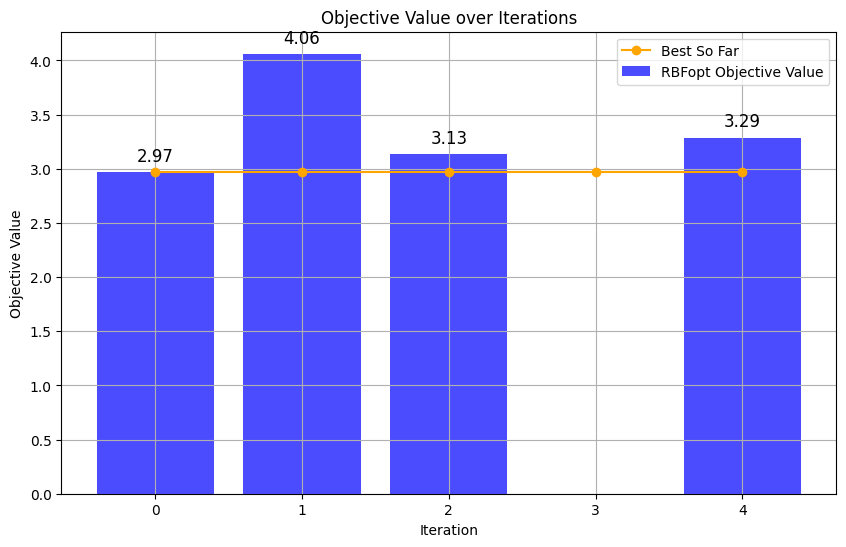

In [7]:
# new iterations data
iterations = [
    (0, 2.965911, [7., 7.]),
    (1, 4.061882, [2., 1.]),
    (2, 3.133784, [4., 4.]),
    (3, float('inf'), [1., 7.]),
    (4, 3.287151, [7., 1.]),
]

# Extract x, y, and objective values
trajectory_x = [point[2][0] for point in iterations]
trajectory_y = [point[2][1] for point in iterations]
trajectory_obj = [point[1] for point in iterations]


LDSDA_iterations = [
    (0, 9.884851863760804, [1., 1.]),
    (1, float('inf'), [1., 2.]),
    (2, 4.061882, [2., 2.]),
    (3, 4.061882, [2., 1.]),
    (4, 3.3148454030723937, [3., 3.]),
    (5, 3.1337838981128, [4., 4.]),
    (6, 3.06201457641079, [5., 5.]),
    (7, 3.0072779729074375, [6., 6.]),
    (8, 2.965911187241821, [7., 7.]),
]

# Plot objective against iteration
plt.figure(figsize=(10, 6))
# Bar plot with objectives for iteration and add a * for inf
plt.bar(range(len(trajectory_obj)), trajectory_obj, color='blue', alpha=0.7, label='RBFopt Objective Value')
# plt.bar(range(len(LDSDA_iterations)), [obj[1] for obj in LDSDA_iterations], color='red', alpha=0.7, label='LD-SDA Objective Value')
for i, obj in enumerate(trajectory_obj):
    if obj == np.inf:
        plt.text(i, obj + 0.1, '*', fontsize=12, color='red', ha='center')
    else:
        plt.text(i, obj + 0.1, f'{obj:.2f}', fontsize=12, color='black', ha='center')

# Ladder plot with the best found solution up until that iterations (minimum value)
best_so_far = [min(trajectory_obj[:i+1]) for i in range(len(trajectory_obj))]
plt.plot(range(len(trajectory_obj)), best_so_far, marker='o', linestyle='-', color='orange', label='Best So Far')

# plt.xticks(range(len(trajectory_obj)), [str(i) for i in range(len(trajectory_obj))])
plt.xlabel('Iteration')
plt.ylabel('Objective Value')

plt.title('Objective Value over Iterations')
plt.legend()
plt.grid()
plt.show()

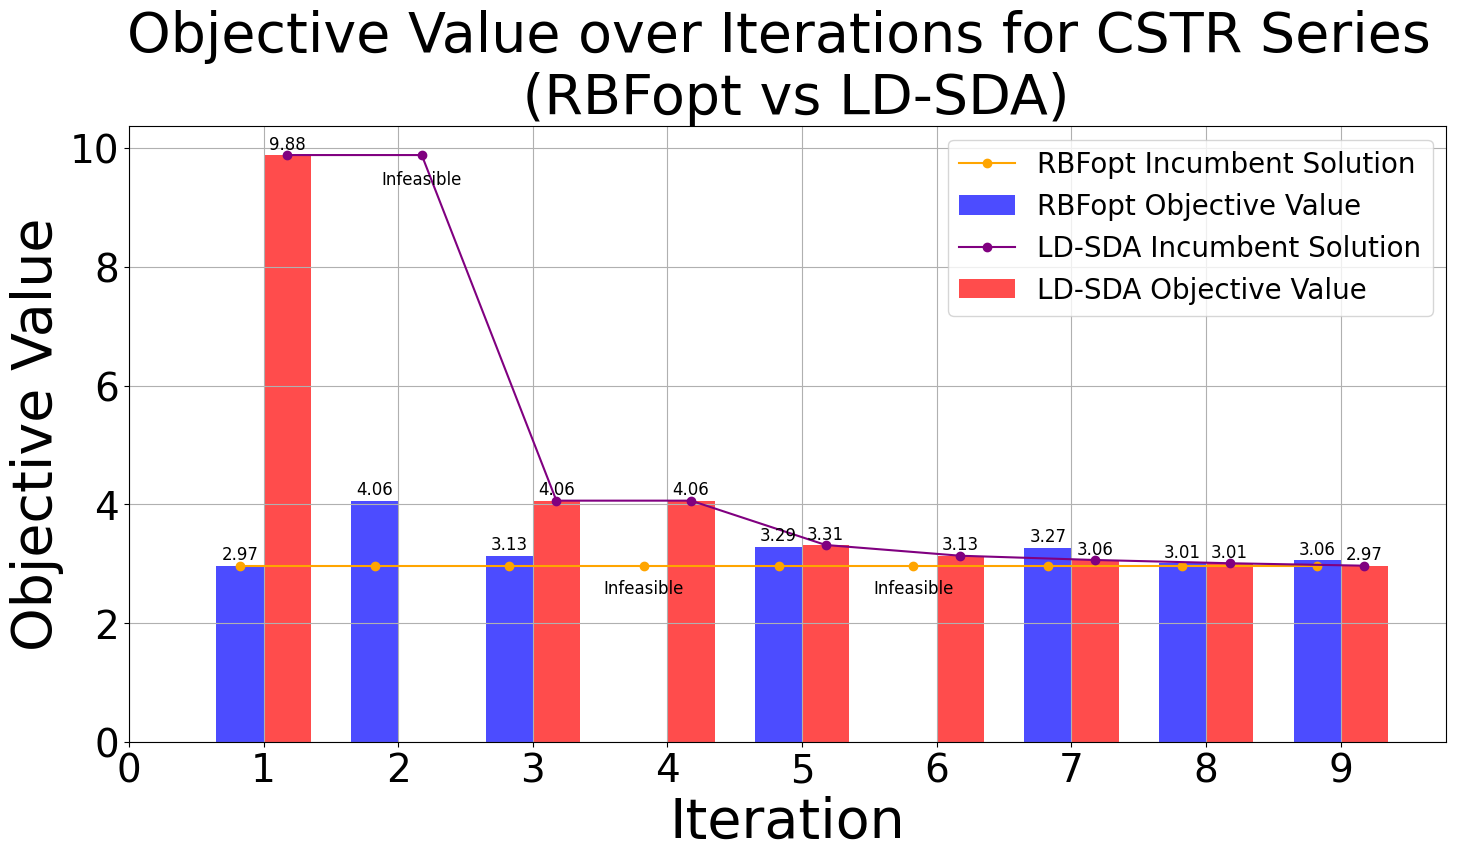

In [8]:
import matplotlib.pyplot as plt
import numpy as np

# # RBFopt iterations data
# iterations = [
#     (1, 2.965911, [7., 7.]),
#     (2, 4.061882, [2., 1.]),
#     (3, 3.133784, [4., 4.]),
#     (4, float('inf'), [1., 7.]),
#     (5, 3.287151, [7., 1.]),
# ]

# 9 iterations data
iterations = [
    (1, 2.965911, [7., 7.]),
    (2, 4.061882, [2., 1.]),
    (3, 3.133784, [4., 4.]),
    (4, float('inf'), [1., 7.]),
    (5, 3.287151, [7., 1.]),
    (6, float('inf'), [6., 7.]),
    (7, 3.269434, [7., 6.]),
    (8, 3.007278, [6., 6.]),
    (9, 3.062015, [5., 5.]),
]

# LD-SDA iterations data
LDSDA_iterations = [
    (1, 9.884851863760804, [1., 1.]),
    (2, float('inf'), [1., 2.]),
    (3, 4.061882, [2., 2.]),
    (4, 4.061882, [2., 1.]),
    (5, 3.3148454030723937, [3., 3.]),
    (6, 3.1337838981128, [4., 4.]),
    (7, 3.06201457641079, [5., 5.]),
    (8, 3.0072779729074375, [6., 6.]),
    (9, 2.965911187241821, [7., 7.]),
]

# Extract iteration indices and objective values
RBFopt_indices = [pt[0] for pt in iterations]
RBFopt_obj = [pt[1] for pt in iterations]

LDSDA_indices = [pt[0] for pt in LDSDA_iterations]
LDSDA_obj = [pt[1] for pt in LDSDA_iterations]

# Calculate best-so-far (ladder plot) for each method
RBFopt_best = [min(RBFopt_obj[:i+1]) for i in range(len(RBFopt_obj))]
LDSDA_best = [min(LDSDA_obj[:i+1]) for i in range(len(LDSDA_obj))]

# For annotations of infeasible bars, determine a fixed y-position
ldsda_feasible = [obj for obj in LDSDA_obj if not np.isinf(obj)]
ldsda_feasible_max = max(ldsda_feasible) if ldsda_feasible else 1

fig, ax = plt.subplots(figsize=(17, 8))
bar_width = 0.35

# Convert indices to numpy arrays for arithmetic
RBFopt_x = np.array(RBFopt_indices, dtype=float)
LDSDA_x = np.array(LDSDA_indices, dtype=float)

# Plot RBFopt bars (shift left)
bars_rbf = ax.bar(RBFopt_x - bar_width/2, RBFopt_obj, width=bar_width,
                  color='blue', alpha=0.7, label='RBFopt Objective Value')
# Annotate RBFopt bars
for x, obj in zip(RBFopt_x, RBFopt_obj):
    if np.isinf(obj):
        ax.text(x - bar_width/2, 2.5, 'Infeasible', fontsize=12, color='black', ha='center')
    else:
        ax.text(x - bar_width/2, obj + 0.1, f'{obj:.2f}', fontsize=12, color='black', ha='center')

# Plot RBFopt best-so-far (ladder) and store its handle
line_rbf, = ax.plot(RBFopt_x - bar_width/2, RBFopt_best, marker='o', linestyle='-', color='orange',
                    label='RBFopt Incumbent Solution')

# Plot LD-SDA bars (shift right)
bars_ldsda = ax.bar(LDSDA_x + bar_width/2, LDSDA_obj, width=bar_width,
                    color='red', alpha=0.7, label='LD-SDA Objective Value')
# Annotate LD-SDA bars
for x, obj in zip(LDSDA_x, LDSDA_obj):
    if np.isinf(obj):
        ax.text(x + bar_width/2, ldsda_feasible_max * 0.95, 'Infeasible', fontsize=12, color='black', ha='center')
    else:
        ax.text(x + bar_width/2, obj + 0.1, f'{obj:.2f}', fontsize=12, color='black', ha='center')

# Plot LD-SDA best-so-far (ladder) and store its handle
line_ldsda, = ax.plot(LDSDA_x + bar_width/2, LDSDA_best, marker='o', linestyle='-', color='purple',
                      label='LD-SDA Incumbent Solution')

# Now manually set the legend order by specifying handles in the desired sequence
ax.legend(
    [line_rbf, bars_rbf, line_ldsda, bars_ldsda], 
    [
        'RBFopt Incumbent Solution',   # 1
        'RBFopt Objective Value',      # 2
        'LD-SDA Incumbent Solution',   # 3
        'LD-SDA Objective Value'       # 4
    ],
    fontsize=20
)

# Labeling and styling
ax.set_xlabel('Iteration', fontsize=40)
ax.set_ylabel('Objective Value', fontsize=40)
ax.set_title('Objective Value over Iterations for CSTR Series \n (RBFopt vs LD-SDA)', fontsize=40)
ax.grid(True)

# Set x-axis ticks
max_iter = max(max(RBFopt_indices), max(LDSDA_indices))
ax.set_xticks(np.arange(0, max_iter + 1, 1))
ax.tick_params(axis='y', labelsize=28)
ax.tick_params(axis='x', labelsize=28)

plt.show()
